In [1]:
pip install matplotlib seaborn plotly

Note: you may need to restart the kernel to use updated packages.


In [9]:
import pandas as pd

In [11]:
import pandas as pd

sales = pd.read_csv("sales_analysis_day5.csv")
orders = pd.read_csv("order_summary_day5.csv")

print(sales.shape)
print(orders.shape)
print(sales.head())
print(orders.head())

(34689, 27)
(11439, 10)
   order_item_id    order_id product_id  quantity unit_price_at_purchase  \
0  ITEM000000001  ORD0000001  PROD00513         2                 120.67   
1  ITEM000000002  ORD0000002  PROD00124         2                  83.58   
2  ITEM000000003  ORD0000002  PROD00631         2                  46.96   
3  ITEM000000004  ORD0000002  PROD00136         1                 100.59   
4  ITEM000000005  ORD0000002  PROD00090         1                 109.18   

   unit_price_clean customer_id order_datetime_clean order_status  \
0            120.67  CUST000839  2025-11-07 17:02:00    Cancelled   
1             83.58  CUST002871  2025-09-18 09:13:00    Completed   
2             46.96  CUST002871  2025-09-18 09:13:00    Completed   
3            100.59  CUST002871  2025-09-18 09:13:00    Completed   
4            109.18  CUST002871  2025-09-18 09:13:00    Completed   

  sales_channel  ...        region_name     city  loyalty_tier   gender   age  \
0   Marketplace  ...  N

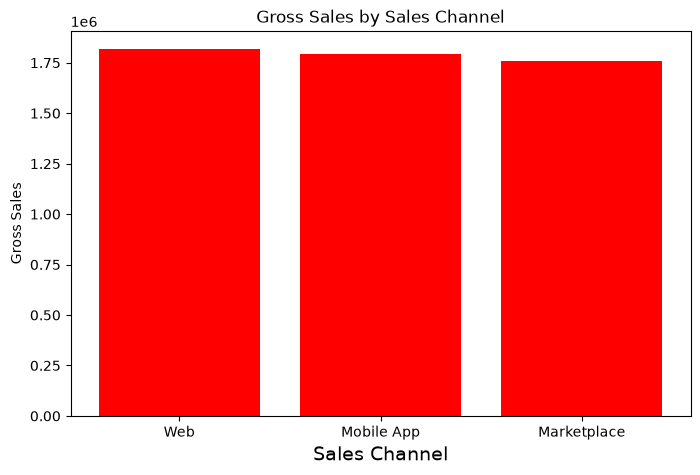

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(["Web", "Mobile App", "Marketplace"], [1816800, 1791324, 1760833],color="RED")
plt.title("Gross Sales by Sales Channel")
plt.xlabel("Sales Channel", fontsize=14)
plt.ylabel("Gross Sales")
plt.show()

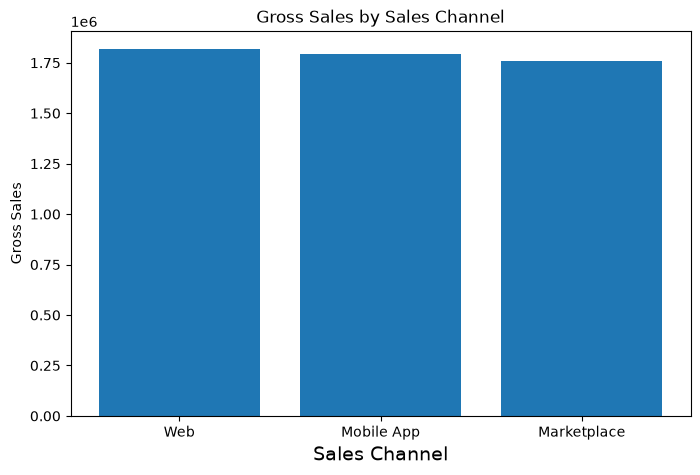

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(["Web", "Mobile App", "Marketplace"], [1816800, 1791324, 1760833])
plt.title("Gross Sales by Sales Channel")
plt.xlabel("Sales Channel", fontsize=14)
plt.ylabel("Gross Sales")
plt.show()

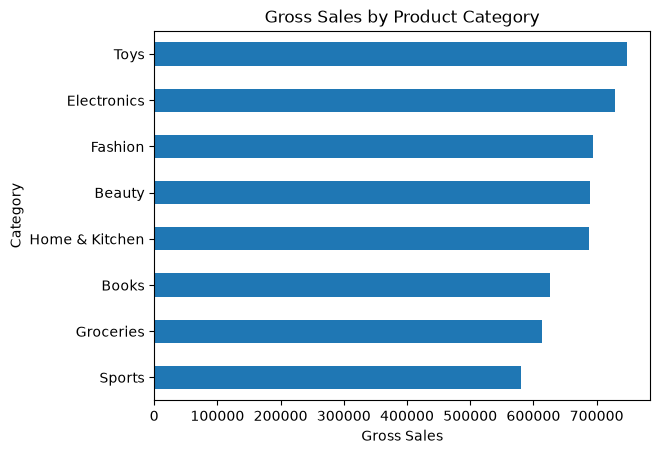

In [14]:
category_sales = (
    sales[sales["order_status"].isin(["Completed", "Shipped"])]
    .groupby("category_clean")["gross_sales"]
    .sum()
    .sort_values(ascending=True)
)

category_sales.plot(kind="barh")
plt.title("Gross Sales by Product Category")
plt.xlabel("Gross Sales")
plt.ylabel("Category")
plt.show()

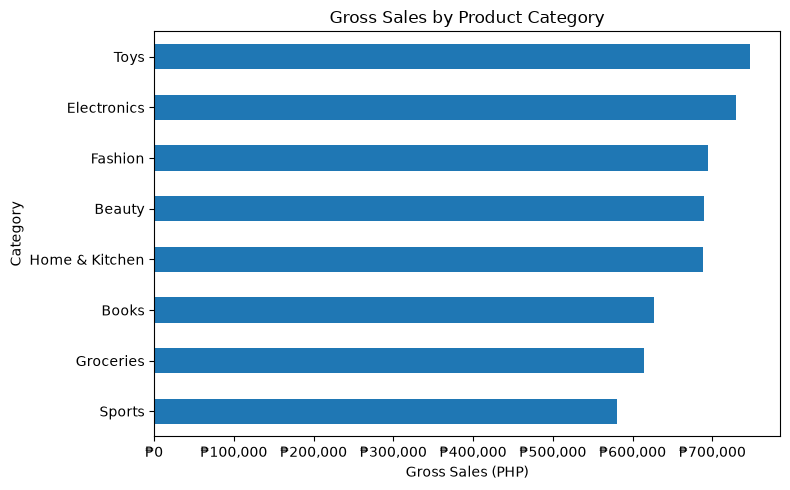

In [15]:
import matplotlib.ticker as mtick

ax = category_sales.plot(kind="barh", figsize=(8, 5))
ax.set_title("Gross Sales by Product Category")
ax.set_xlabel("Gross Sales (PHP)")
ax.set_ylabel("Category")
ax.xaxis.set_major_formatter(
    mtick.StrMethodFormatter("₱{x:,.0f}")
)

plt.tight_layout()
plt.show()

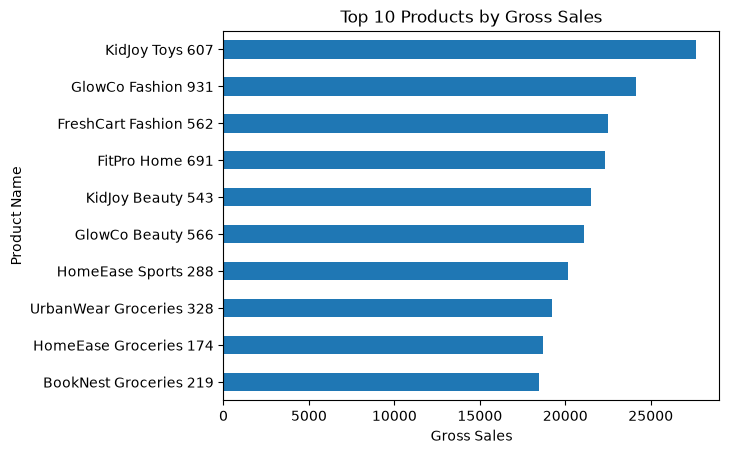

In [31]:
fulfilled = sales[sales["order_status"].isin(["Completed", "Shipped"])]
top_products = (
    fulfilled
    .groupby("product_name")["gross_sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

top_products.plot(kind="barh")
plt.title("Top 10 Products by Gross Sales")
plt.xlabel("Gross Sales")
plt.ylabel("Product Name")
plt.show()

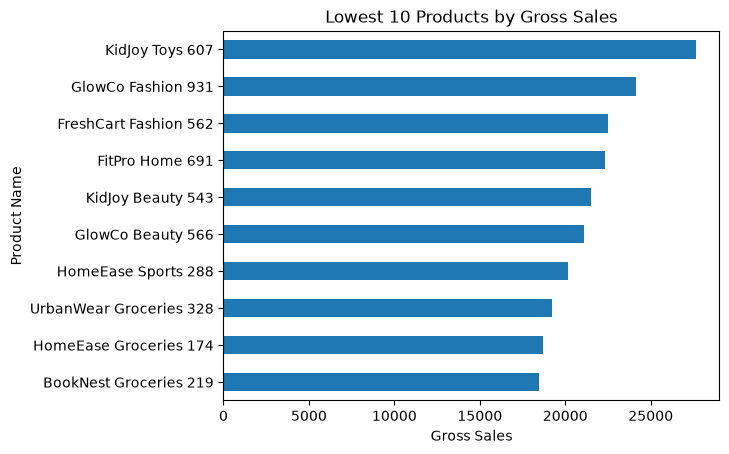

In [32]:
fulfilled = sales[sales["order_status"].isin(["Completed", "Shipped"])]
lowest_products = (
    fullfilled
    .groupby("product_name")["gross_sales"]
    .sum()
    .sort_values(ascending=False)
    .tail(10)
    .sort_values()
)

top_products.plot(kind="barh")
plt.title("Lowest 10 Products by Gross Sales")
plt.xlabel("Gross Sales")
plt.ylabel("Product Name")
plt.show()

In [33]:
top_products

product_name
BookNest Groceries 219     18447.52
HomeEase Groceries 174     18671.00
UrbanWear Groceries 328    19208.70
HomeEase Sports 288        20175.30
GlowCo Beauty 566          21109.92
KidJoy Beauty 543          21477.52
FitPro Home 691            22338.38
FreshCart Fashion 562      22502.01
GlowCo Fashion 931         24151.49
KidJoy Toys 607            27642.51
Name: gross_sales, dtype: float64

In [34]:
lowest_products

product_name
Acme Electronics 362          997.48
SunPeak Books 482            1024.40
UrbanWear Electronics 232    1065.00
NovaTech Electronics 912     1073.52
HomeEase Fashion 863         1254.42
UrbanWear Beauty 979         1319.40
NovaTech Electronics 398     1337.56
HomeEase Groceries 301       1395.36
KidJoy Toys 225              1409.40
KidJoy Beauty 857            1419.11
Name: gross_sales, dtype: float64

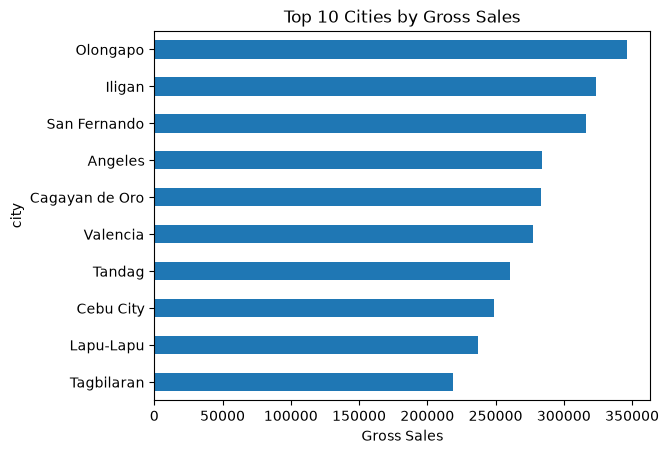

In [35]:
top_cities = (
    fulfilled
    .groupby("city")["gross_sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

top_cities.plot(kind="barh")
plt.title("Top 10 Cities by Gross Sales")
plt.xlabel("Gross Sales")
plt.show()

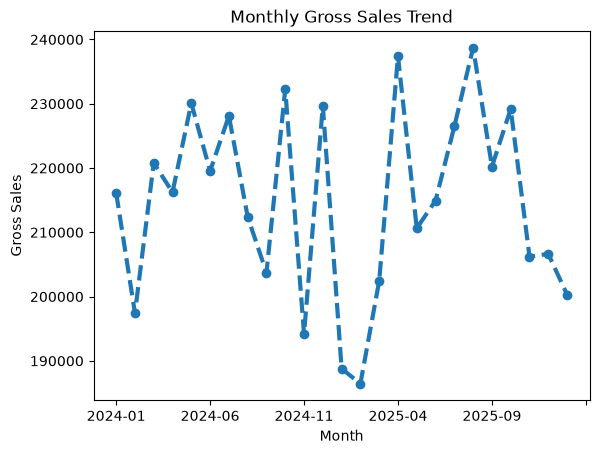

In [42]:
monthly_sales = (
    fulfilled
    .groupby("month")["gross_sales"]
    .sum()
    .sort_index()
)

monthly_sales.plot(kind="line", marker="o", linestyle = "--", linewidth = 3) #can use difft marker for matplotlib just google search it
plt.title("Monthly Gross Sales Trend")
plt.xlabel("Month")
plt.ylabel("Gross Sales")
plt.show()

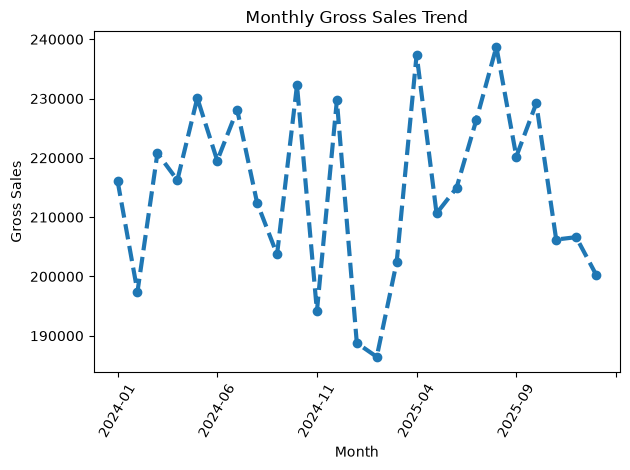

In [43]:
monthly_sales = (
    fullfilled
    .groupby("month")["gross_sales"]
    .sum()
    .sort_index()
)

monthly_sales.plot(kind="line", marker="o", linestyle="--", linewidth=3)
plt.title("Monthly Gross Sales Trend")
plt.xlabel("Month")
plt.ylabel("Gross Sales")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()


In [44]:
monthly_sales

month
2024-01    216149.36
2024-02    197434.52
2024-03    220788.11
2024-04    216238.83
2024-05    230084.14
2024-06    219534.24
2024-07    228106.08
2024-08    212410.13
2024-09    203718.12
2024-10    232258.29
2024-11    194157.86
2024-12    229690.46
2025-01    188781.26
2025-02    186446.25
2025-03    202420.33
2025-04    237421.03
2025-05    210631.87
2025-06    214933.34
2025-07    226463.23
2025-08    238720.38
2025-09    220217.00
2025-10    229185.04
2025-11    206222.77
2025-12    206627.40
2026-01    200316.89
Name: gross_sales, dtype: float64

Text(0.5, 1.0, 'Fulfilled Orders by Month')

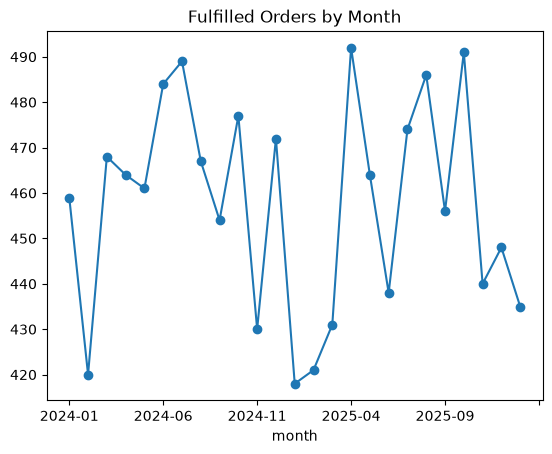

In [46]:
monthly_orders = (
    orders.groupby("month")["order_id"]
    .nunique()
)

monthly_orders.plot(kind = "line", marker = "o")
plt.title("Fulfilled Orders by Month")

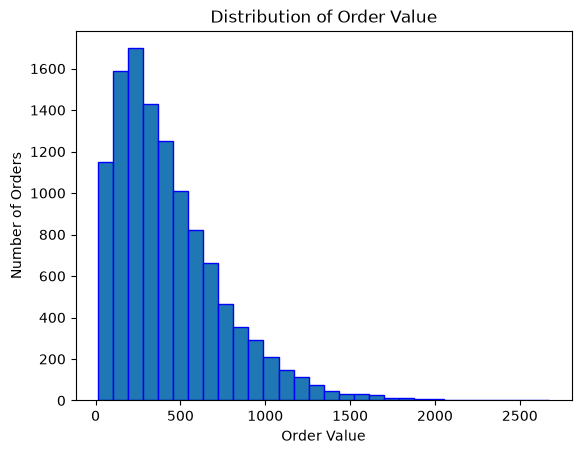

In [47]:
plt.hist(
    orders["order_value"],
    bins=30,
    edgecolor="#00F"
)

plt.title("Distribution of Order Value")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")
plt.show()

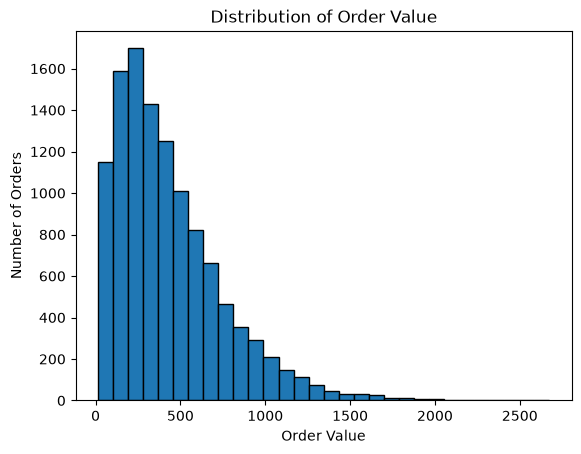

In [48]:
plt.hist(
    orders["order_value"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Order Value")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")
plt.show()

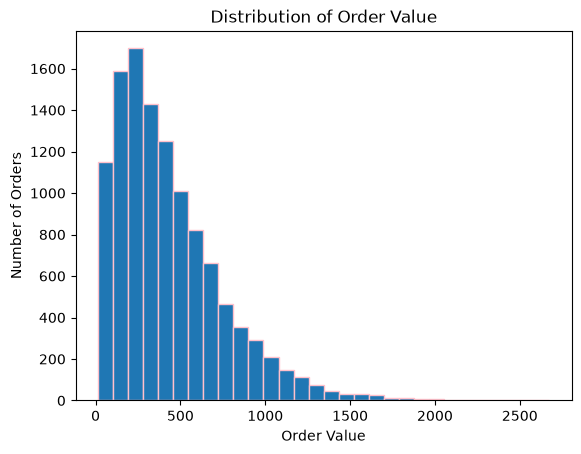

In [49]:
plt.hist(
    orders["order_value"],
    bins=30,
    edgecolor="pink"
)

plt.title("Distribution of Order Value")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")
plt.show()

In [50]:
import numpy as np
np.median(orders["order_value"])

np.float64(358.934)

In [51]:
import numpy as np
np.mean(orders["order_value"])

np.float64(434.35123258414194)

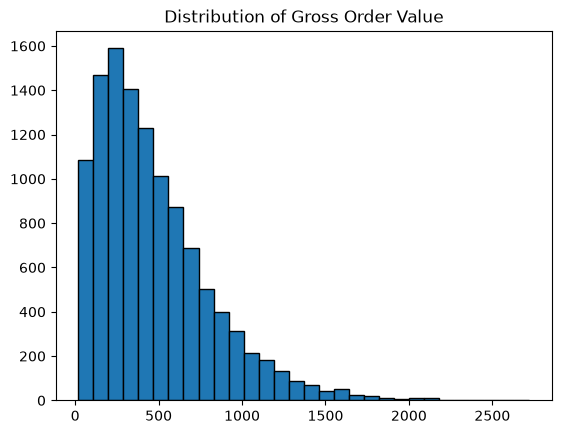

In [52]:
plt.hist(
    orders["gross_order_value"],
    bins=30,
    edgecolor="black"
)
plt.title("Distribution of Gross Order Value")
plt.show()

In [53]:
np.mean(orders["gross_order_value"])

np.float64(469.35544453186463)

In [54]:
np.median(orders["gross_order_value"])

np.float64(390.1)

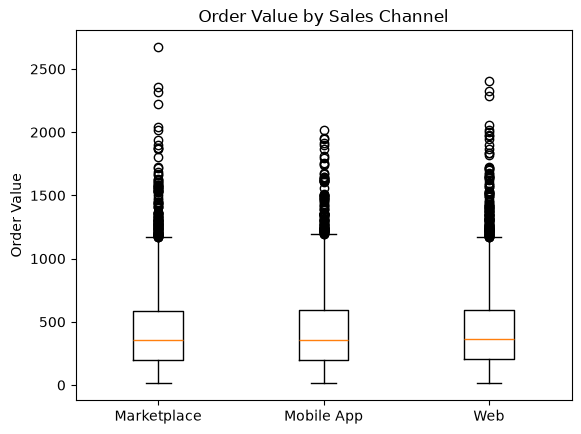

In [55]:
channels = [
    "Marketplace",
    "Mobile App",
    "Web"
]

values = [
    orders.loc[
        orders["sales_channel"] == channel,
        "order_value"
    ]
    for channel in channels
]

plt.boxplot(
    values,
    tick_labels=channels
)

plt.title("Order Value by Sales Channel")
plt.ylabel("Order Value")
plt.show()


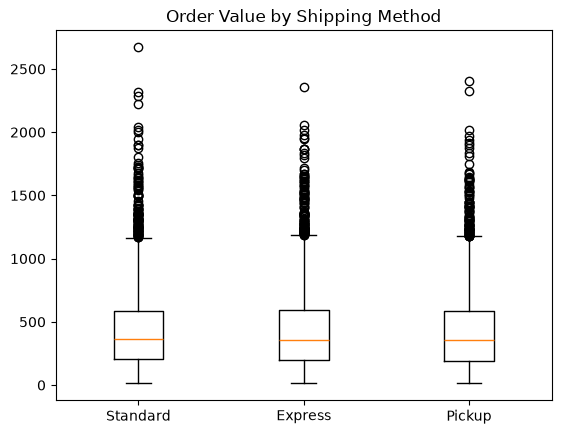

In [60]:
shipping_groups = [
    orders.loc[
        orders["shipping_method"] == method,
        "order_value"
    ]
    for method in ["Standard", "Express", "Pickup"]
]

plt.boxplot(
    shipping_groups,
    tick_labels=["Standard", "Express", "Pickup"]
)

plt.title("Order Value by Shipping Method")
plt.show()


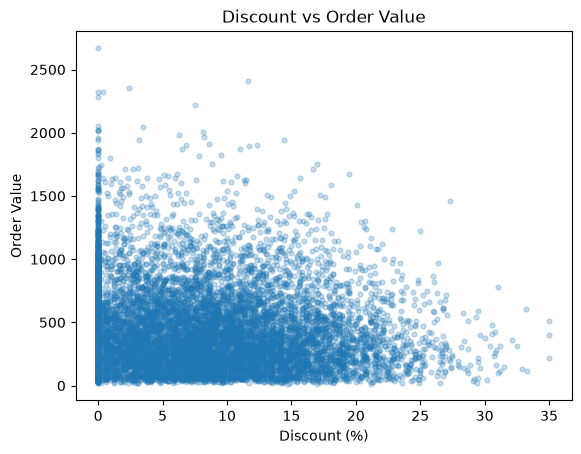

In [61]:
plt.scatter(
    orders["discount_pct"] * 100,
    orders["order_value"],
    alpha=0.25,
    s=12
)

plt.title("Discount vs Order Value")
plt.xlabel("Discount (%)")
plt.ylabel("Order Value")
plt.show()

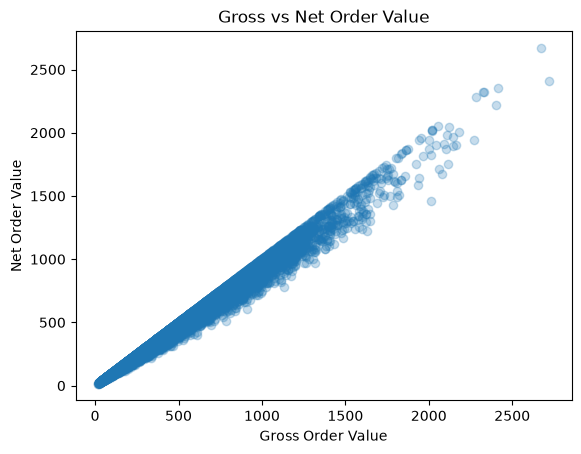

In [62]:
plt.scatter(
    orders["gross_order_value"],
    orders["order_value"],
    alpha=0.25
)

plt.xlabel("Gross Order Value")
plt.ylabel("Net Order Value")
plt.title("Gross vs Net Order Value")
plt.show()

In [63]:
import seaborn as sns
import matplotlib.pyplot as plt

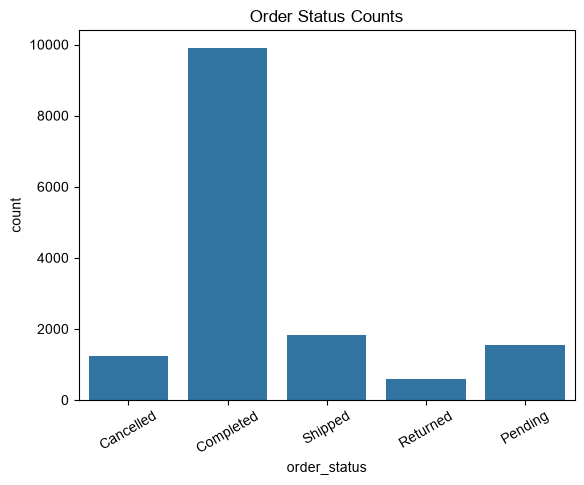

In [64]:
# Seaborn works directly with DataFrame columns
orders_raw = pd.read_csv("datasets/orders.csv")
sns.countplot(data=orders_raw, x="order_status")
sns.set_theme(style="darkgrid")
plt.title("Order Status Counts")
plt.xticks(rotation=30)
plt.show()

In [65]:
orders_raw

,order_id,customer_id,order_datetime,order_status,sales_channel,shipping_method,discount_pct,shipping_fee
0,ORD0000001,CUST000839,2025-11-07 17:02:00,Cancelled,Marketplace,Standard,0.074,102.68
1,ORD0000002,CUST002871,09/18/2025 09:13 AM,Completed,Marketplace,Express,0.063,0.00
2,ORD0000003,CUST000720,2025-08-08 04:59:00,Completed,Web,Standard,0.137,103.83
3,ORD0000004,CUST002515,2025-10-14 12:56:00,Completed,Web,Pickup,0.005,112.69
4,ORD0000005,CUST001544,2024-05-30 04:56:00,Completed,Marketplace,Pickup,NaN,111.73
...,...,...,...,...,...,...,...,...
15070,ORD0011300,CUST000701,2024-11-17 21:58:00,Cancelled,Marketplace,Express,0.036,75.40
15071,ORD0014948,CUST003808,28-Dec-2025 01:01,Completed,Mobile App,Standard,0.019,142.29
15072,ORD0012066,CUST004052,2025-05-04 06:07:00,Completed,Web,Standard,0.087,107.84
15073,ORD0012132,CUST002798,2025-04-29 21:11:00,Completed,Mobile App,Pickup,0.062,82.12


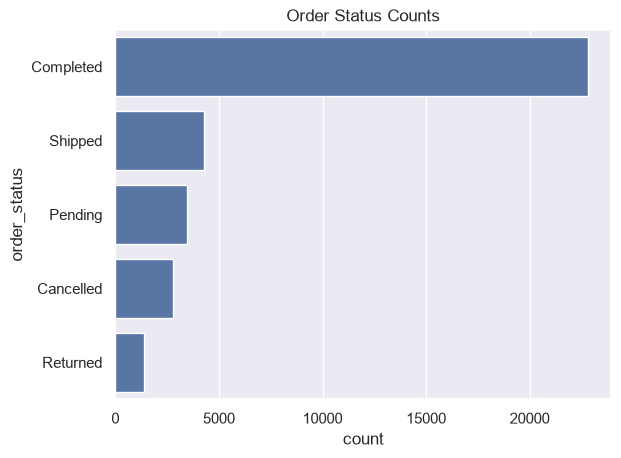

In [66]:
sns.countplot(
    data=sales,
    y="order_status",
    order=sales[
        "order_status"
    ].value_counts().index
)

plt.title("Order Status Counts")
plt.show()

In [67]:
order=sales[
        "order_status"
    ].value_counts().index

In [68]:
order

Index(['Completed', 'Shipped', 'Pending', 'Cancelled', 'Returned'], dtype='str', name='order_status')

In [69]:
payments = pd.read_csv("datasets/payments.csv")

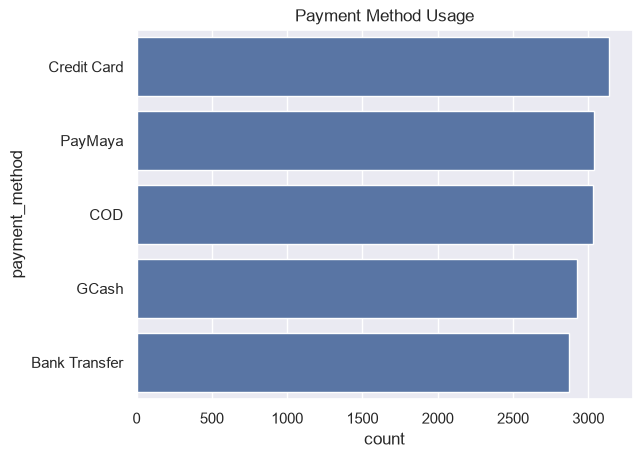

In [70]:
sns.countplot(
    data=payments,
    y="payment_method",
    order=payments[
        "payment_method"
    ].value_counts().index
)

plt.title("Payment Method Usage")
plt.show()


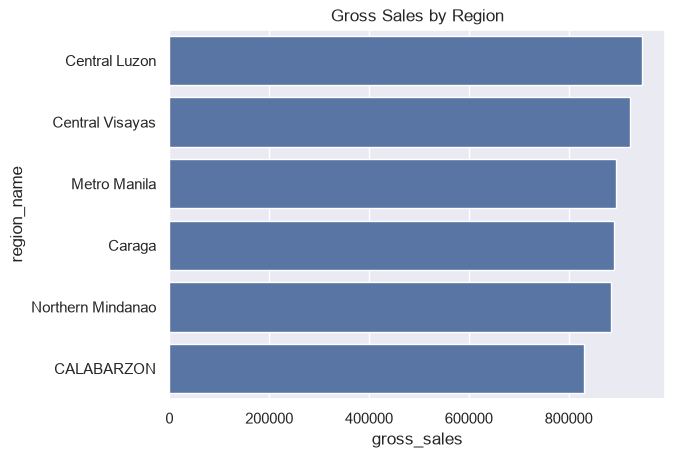

In [71]:
region_sales = (
    fullfilled
    .groupby(
        "region_name",
        as_index=False
    )["gross_sales"]
    .sum()
    .sort_values(
        "gross_sales",
        ascending=False
    )
)

sns.barplot(
    data=region_sales,
    y="region_name",
    x="gross_sales"
)

plt.title("Gross Sales by Region")
plt.show()


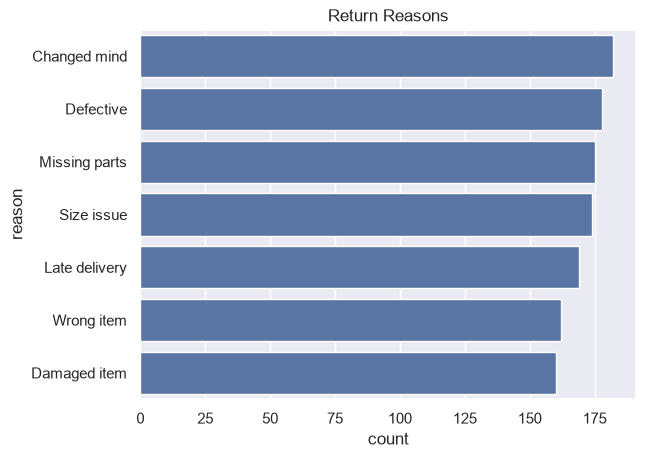

In [72]:
returns = pd.read_csv("datasets/returns.csv")
return_reason_counts = (
    returns["reason"]
    .value_counts()
    .rename_axis("reason")
    .reset_index(name="count")
)

sns.barplot(
    data=return_reason_counts,
    y="reason",
    x="count"
)

plt.title("Return Reasons")
plt.show()

In [73]:
region_sales

,region_name,gross_sales
2,Central Luzon,946439.93
3,Central Visayas,922410.25
4,Metro Manila,895059.62
1,Caraga,889957.29
5,Northern Mindanao,884281.49
0,CALABARZON,830808.35


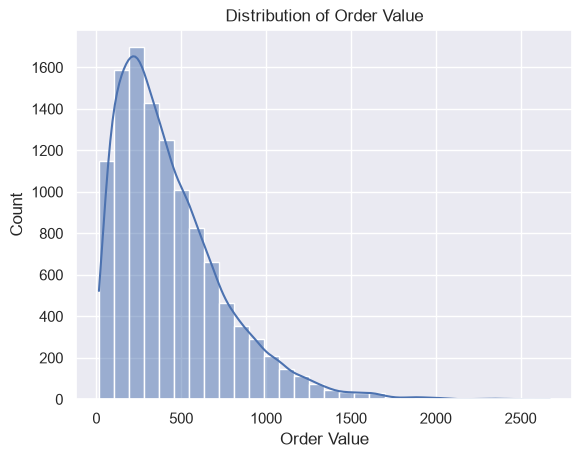

In [74]:
sns.histplot(
    data=orders,
    x="order_value",
    bins=30,
    kde=True
)

plt.title("Distribution of Order Value")
plt.xlabel("Order Value")
plt.show()

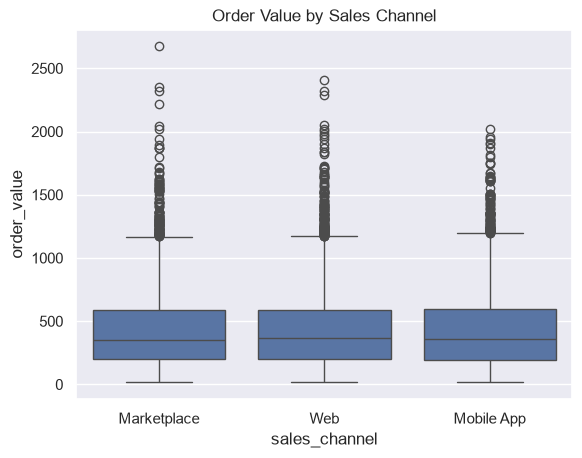

In [75]:
sns.boxplot(
    data=orders,
    x="sales_channel",
    y="order_value"
)

plt.title("Order Value by Sales Channel")
plt.show()


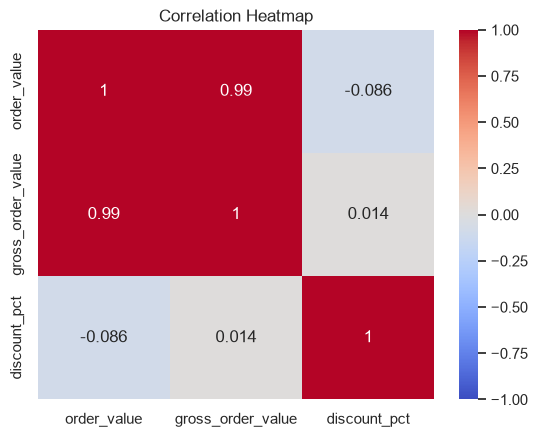

In [76]:
corr = orders[[
    "order_value",
    "gross_order_value",
    "discount_pct"
]].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.show()


In [77]:
import plotly.express as px

In [78]:
fulfilled_sales = sales[
    sales["order_status"].isin(["Completed", "Shipped"])
].copy()

In [79]:
category_sales_df = (
    fulfilled_sales
    .groupby("category_clean", as_index = False)["gross_sales"]
    .sum()
    .sort_values("gross_sales", ascending=True)
)

In [80]:
category_sales_df

,category_clean,gross_sales
6,Sports,579856.62
4,Groceries,613774.68
1,Books,626243.53
5,Home & Kitchen,688160.85
0,Beauty,689454.74
3,Fashion,694577.62
2,Electronics,729573.33
7,Toys,747315.56


In [81]:
import plotly.io as pio

In [82]:
pio.renderers.default = "notebook"

In [83]:
fig = px.bar(
    category_sales_df,
    x="gross_sales",
    y="category_clean",
    orientation="h",
    title="Gross Sales by Category"
)

fig.show()

In [84]:
category_sales_df = (
    fullfilled
    .groupby(
        "category_clean",
        as_index=False
    )["gross_sales"]
    .sum()
    .sort_values("gross_sales")
)

fig = px.bar(
    category_sales_df,
    x="gross_sales",
    y="category_clean",
    orientation="h",
    title="Gross Sales by Category",
    labels={
        "gross_sales": "Gross Sales",
        "category_clean": "Category"
    }
)

fig.show()


In [85]:
fig = px.bar(
    region_sales,
    x="gross_sales",
    y="region_name",
    orientation="h",
    title="Gross Sales by Region"
)

fig.show()


In [86]:
monthly_df = (
    fullfilled
    .groupby(
        "month",
        as_index=False
    )["gross_sales"]
    .sum()
    .sort_values("month")
)

fig = px.line(
    monthly_df,
    x="month",
    y="gross_sales",
    markers=True,
    title="Monthly Gross Sales Trend"
)

fig.show()


In [87]:
monthly_orders = (
    orders.groupby(
        "month",
        as_index=False
    )["order_id"]
    .nunique()
)

fig = px.line(
    monthly_orders,
    x="month",
    y="order_id",
    markers=True,
    title="Fulfilled Orders per Month"
)

fig.show()


In [88]:
fig = px.scatter(
    orders,
    x="discount_pct",
    y="order_value",
    color="sales_channel",
    hover_data=[
        "order_id",
        "region_name"
    ],
    title="Discount vs Order Value by Channel"
)

fig.show()


In [89]:
fig = px.scatter(
    orders,
    x="gross_order_value",
    y="order_value",
    color="sales_channel",
    hover_data=["order_id"]
)

fig.show()


In [103]:
fulfilled = sales[
    sales["order_status"]
    .isin(["Completed", "Shipped"])
]

total_sales = (
    fulfilled["gross_sales"].sum()
)

order_count = (
    fulfilled["order_id"].nunique()
)

aov = orders["order_value"].mean()

top_category = (
    fulfilled
    .groupby("category_clean")[
        "gross_sales"
    ]
    .sum()
    .idxmax()
)

print(f"Total Sales: {total_sales}")
print(f"Order Count: {order_count}")
print(f"AOV: {aov}")
print(f"Top Category: {top_category}")

Total Sales: 5368956.93
Order Count: 11439
AOV: 434.35123258414194
Top Category: Toys


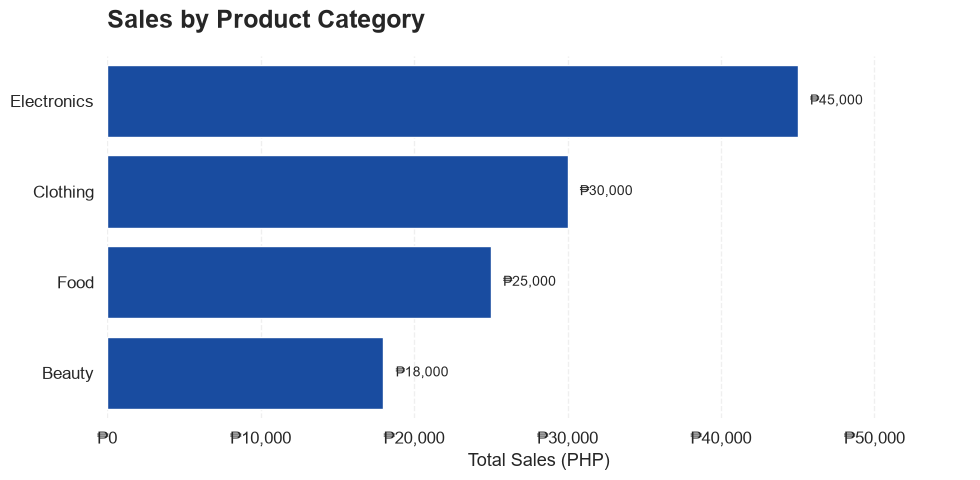

In [108]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Set Seaborn theme
sns.set_theme(
    style="whitegrid",
    palette="deep",
    font_scale=1.1
)

fig, ax = plt.subplots(figsize=(10, 5))

# Create chart
sns.barplot(
    data=df,
    x="sales",
    y="category",
    color="#0247B7",
    errorbar=None,
    ax=ax
)

# Title and labels
ax.set_title(
    "Sales by Product Category",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=20
)

ax.set_xlabel("Total Sales (PHP)")
ax.set_ylabel("")

# Format numbers
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"₱{x:,.0f}")
)

# Add sales labels
for bar in ax.patches:
    value = bar.get_width()
    ax.text(
        value + 800,
        bar.get_y() + bar.get_height() / 2,
        f"₱{value:,.0f}",
        va="center",
        fontsize=10
    )

ax.set_xlim(0, df["sales"].max() * 1.25)

# Improve chart appearance
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.grid(axis="y", visible=False)

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()


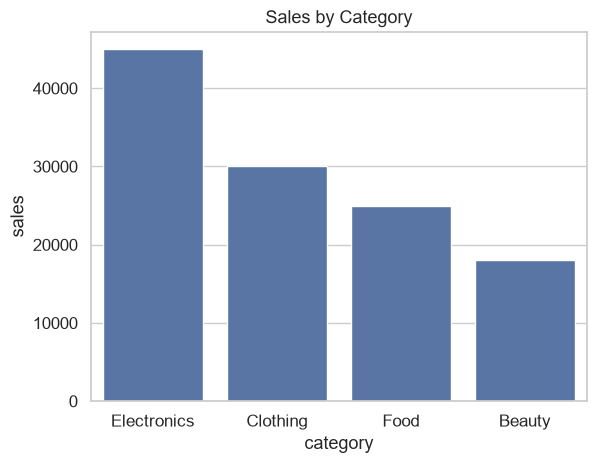

In [109]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

df = pd.DataFrame({
    "category": ["Electronics", "Clothing", "Food", "Beauty"],
    "sales": [45000, 30000, 25000, 18000]
})

sns.barplot(
    data=df,
    x="category",
    y="sales"
)

plt.title("Sales by Category")
plt.show()